In [1]:
import random 
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    roc_auc_score,
    average_precision_score
)

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow version:", tf.__version__)

2026-11-02 16:04:24.238122: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
/Users/michelino/Desktop/RT-IoT2022-Anomaly-Detection/.venv/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


TensorFlow version: 2.16.2


In [2]:
X_train = pd.read_csv("../data/processed/X_train.csv")
X_val = pd.read_csv("../data/processed/X_val.csv")
X_test = pd.read_csv("../data/processed/X_test.csv")

train_metadata = pd.read_csv(
    "../data/processed/train_metadata.csv"
)

val_metadata = pd.read_csv(
    "../data/processed/val_metadata.csv"
)

test_metadata = pd.read_csv(
    "../data/processed/test_metadata.csv"
)

print("Training set:", X_train.shape)
print("Validation set:", X_val.shape)
print("Test set:", X_test.shape)


Training set: (7209, 92)
Validation set: (55356, 92)
Test set: (55357, 92)


In [3]:
y_val = (
    val_metadata["Label"] == "Anomaly"
).astype(int).to_numpy()

y_test = (
    test_metadata["Label"] == "Anomaly" 
).astype(int).to_numpy()

print("Validation labels:")
print(pd.Series(y_val).value_counts())

print("\nTest labels:")
print(pd.Series(y_test).value_counts())

Validation labels:
1    52953
0     2403
Name: count, dtype: int64

Test labels:
1    52954
0     2403
Name: count, dtype: int64


In [4]:
X_train_np = X_train.to_numpy(dtype=np.float32)
X_val_np = X_val.to_numpy(dtype=np.float32)
X_test_np = X_test.to_numpy(dtype=np.float32)

print("X_train:", X_train_np.shape, X_train_np.dtype)
print("X_val:", X_val_np.shape, X_val_np.dtype)
print("X_test:", X_test_np.shape, X_test_np.dtype)

X_train: (7209, 92) float32
X_val: (55356, 92) float32
X_test: (55357, 92) float32


In [5]:
print(
    "NaN in training:",
    np.isnan(X_train_np).sum()
)

print(
    "NaN in validation:",
    np.isnan(X_val_np).sum()
)

print(
    "NaN in test:",
    np.isnan(X_test_np).sum()
)

print(
    "Infinite values in training:",
    np.isinf(X_val_np).sum()
)

print(
    "Infinite values in validation:",
    np.isinf(X_val_np).sum()
)

print(
    "Infinite values in test:",
    np.isinf(X_test_np).sum()
)

NaN in training: 0
NaN in validation: 0
NaN in test: 0
Infinite values in training: 0
Infinite values in validation: 0
Infinite values in test: 0


In [6]:
input_dim = X_train_np.shape[1]
baseline_latent_dim = 16

baseline_model = keras.Sequential(
    [
        layers.Input(shape=(input_dim,)),

        layers.Dense(
            64,
            activation="relu"
        ),

        layers.Dense(
            32,
            activation="relu"
        ),

        layers.Dense(
            baseline_latent_dim,
            activation="relu",
            name="latent_space"
        ),

        layers.Dense(
            32,
            activation="relu"
        ),

        layers.Dense(
            64,
            activation="relu"
        ),

        layers.Dense(
            input_dim,
            activation="linear"
        )
    ],
    name="baseline_autoencoder"
)

baseline_model.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="mae"
)

baseline_model.summary()

Model: "baseline_autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         5,952 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ latent_space (Dense)            │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │           544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 92)             │         5,980 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 17,196 (67.17 KB)

 Trainable params: 17,196 (67.17 KB)

 Non-trainable params: 0 (0.00 B)

In [7]:
early_stopping = keras.callbacks.EarlyStopping(
    monitor = "val_loss",
    patience = 8,
    min_delta = 1e-5,
    restore_best_weights = True
)

In [8]:
history = baseline_model.fit(
    X_train_np,
    X_train_np,
    
    epochs = 100,
    batch_size = 128,
    
    validation_split = 0.15,
    
    shuffle = True,
    
    callbacks = [
        early_stopping
    ],
    
    verbose = 1
)

Epoch 1/100
48/48 ━━━━━━━━━━━━━━━━━━━━ 4s 21ms/step - loss: 0.3761 - val_loss: 0.2792
Epoch 2/100
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.2289 - val_loss: 0.1170
Epoch 3/100
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.1088 - val_loss: 0.0907
Epoch 4/100
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0866 - val_loss: 0.0804
Epoch 5/100
48/48 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0778 - val_loss: 0.0778
Epoch 6/100
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0754 - val_loss: 0.0769
Epoch 7/100
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0745 - val_loss: 0.0765
Epoch 8/100
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0738 - val_loss: 0.0741
Epoch 9/100
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0700 - val_loss: 0.0595
Epoch 10/100
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0559 - val_loss: 0.0522
Epoch 11/100
48/48 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0517 - val_loss: 0.0505
Epoch 12/100
48/48 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 

In [9]:
print(
    "Epochs trained:",
    len(history.history["loss"])
)

print(
    "Final training loss:",
    history.history["loss"][-1]
)

print(
    "Best validation loss:",
    min(history.history["val_loss"])
)

Epochs trained: 100
Final training loss: 0.03982454538345337
Best validation loss: 0.04010024294257164


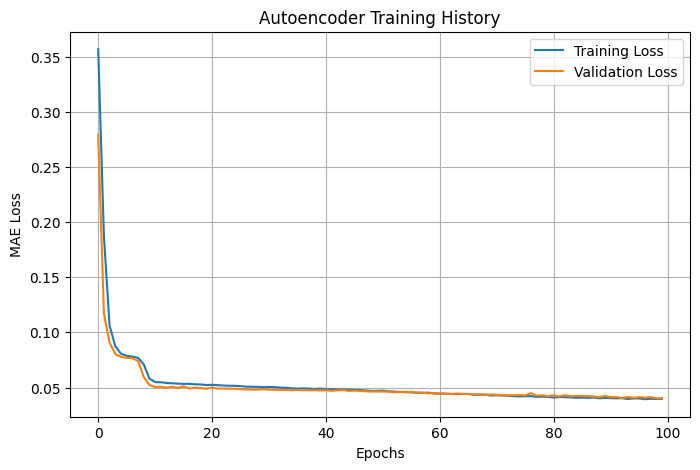

Training reconstruction errors: (7209,)
Validation reconstruction errors: (55356,)


In [10]:
plt.figure(figsize=(8,5))

plt.plot(
    history.history["loss"],
    label = "Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label = "Validation Loss"
)
plt.xlabel("Epochs")
plt.ylabel("MAE Loss")
plt.title("Autoencoder Training History")

plt.legend()
plt.grid()

plt.show()

train_reconstructed = baseline_model.predict(
    X_train_np,
    batch_size = 256,
    verbose = 0
)

val_reconstructed = baseline_model.predict(
    X_val_np,
    batch_size = 256,
    verbose = 0
)

train_errors = np.mean(
    np.abs(
        X_train_np - train_reconstructed
    ),
    axis = 1
)

val_errors = np.mean(
    np.abs(
        X_val_np - val_reconstructed
    ),
    axis = 1
)

print(
    "Training reconstruction errors:",
    train_errors.shape
)

print(
    "Validation reconstruction errors:",
    val_errors.shape
)

In [11]:
train_reconstructed = baseline_model.predict(
    X_train_np,
    batch_size = 256,
    verbose = 0
)

val_reconstructed = baseline_model.predict(
    X_val_np,
    batch_size = 256,
    verbose = 0
)

train_errors = np.mean(
    np.abs(
        X_train_np - train_reconstructed
    ),
    axis = 1
)

val_errors = np.mean(
    np.abs(
        X_val_np - val_reconstructed
    ),
    axis = 1
)

print(
    "Training reconstruction errors:",
    train_errors.shape
)

print(
    "Validation reconstruction errors:",
    val_errors.shape
)

Training reconstruction errors: (7209,)
Validation reconstruction errors: (55356,)


In [12]:
val_normal_errors = val_errors[
    y_val == 0
]

val_anomaly_errors = val_errors[
    y_val == 1
]

error_summary = pd.DataFrame(
   {
       "Training normal": [
           np.mean(train_errors),
           np.median(train_errors),
           np.std(train_errors),
           np.percentile(train_errors, 95),
           np.percentile(train_errors, 99),
           np.max(train_errors)
       ],
       
       "Validation normal": [
           np.mean(val_normal_errors),
           np.median(val_normal_errors),
           np.std(val_normal_errors),
           np.percentile(val_normal_errors, 95),
           np.percentile(val_normal_errors, 99),
           np.max(val_normal_errors)
       ],
       
       "Validation anomaly": [
           np.mean(val_anomaly_errors),
           np.median(val_anomaly_errors),
           np.std(val_anomaly_errors),
           np.percentile(val_anomaly_errors, 95),
           np.percentile(val_anomaly_errors, 99),
           np.max(val_anomaly_errors)
       ]
   },
   
   index = [
       "mean",
       "median",
       "std",
       "p95",
       "p99",
       "max"
   ]
)

error_summary

,Training normal,Validation normal,Validation anomaly
mean,0.039521,0.037424,91.079422
median,0.016851,0.016592,57.545738
std,0.116957,0.111690,86.741516
p95,0.118307,0.091571,244.619690
p99,0.534146,0.575662,244.634598
max,2.730461,2.015277,244.637314


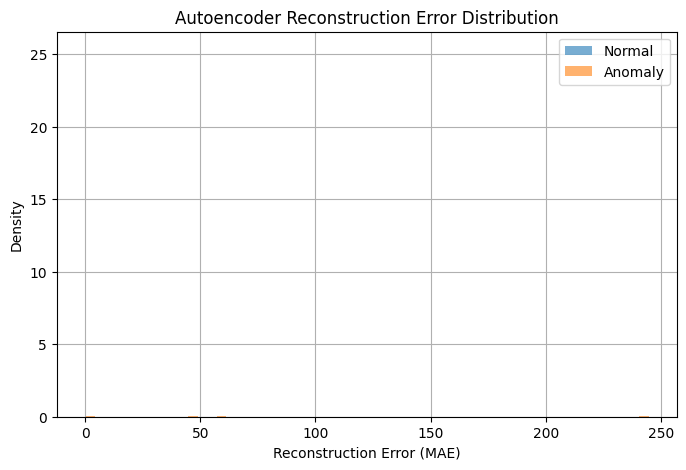

In [13]:
plt.figure(figsize=(8,5))

plt.hist(
    val_normal_errors,
    bins = 60,
    density = True,
    alpha = 0.6,
    label = "Normal"
)

plt.hist(
    val_anomaly_errors,
    bins = 60,
    density = True,
    alpha = 0.6,
    label = "Anomaly"
)

plt.xlabel("Reconstruction Error (MAE)")
plt.ylabel("Density")

plt.title(
    "Autoencoder Reconstruction Error Distribution"
)

plt.legend()
plt.grid()

plt.show()

In [14]:
baseline_threshold = np.max(
    train_errors
)

print(
    "Baseline threshold:",
    baseline_threshold
)

baseline_predictions = (
    val_errors > baseline_threshold
).astype(int)

baseline_cm = confusion_matrix(
    y_val,
    baseline_predictions
)

print("Confusion Matrix:")
print(baseline_cm)

tn, fp, fn, tp = baseline_cm.ravel()

print("\nTrue Negatives:", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives:", tp)

baseline_accuracy = accuracy_score(
    y_val,
    baseline_predictions
)

baseline_precision = precision_score(
    y_val,
    baseline_predictions
)

baseline_recall = recall_score(
    y_val,
    baseline_predictions
)

baseline_f1 = f1_score(
    y_val,
    baseline_predictions
)

baseline_balanced_accuracy = (
    balanced_accuracy_score(
        y_val,
        baseline_predictions
    )
)

baseline_fpr = fp / (fp + tn)

print(
    "Accuracy:",
    baseline_accuracy
)

print(
    "Precision:",
    baseline_precision
)

print(
    "Recall:",
    baseline_recall
)

print(
    "F1-score:",
    baseline_f1
)

print(
    "Balanced Accuracy:",
    baseline_balanced_accuracy
)

print(
    "False Positive Rate:",
    baseline_fpr
)

baseline_roc_auc = roc_auc_score(
    y_val,
    val_errors
)

baseline_pr_auc = (
    average_precision_score(
        y_val,
        val_errors
    )
)

print(
    "ROC-AUC:",
    baseline_roc_auc
)

print(
    "PR-AUC:",
    baseline_pr_auc
)

Baseline threshold: 2.7304606
Confusion Matrix:
[[ 2403     0]
 [10447 42506]]

True Negatives: 2403
False Positives: 0
False Negatives: 10447
True Positives: 42506
Accuracy: 0.8112761037647229
Precision: 1.0
Recall: 0.8027118388004457
F1-score: 0.8905603452791251
Balanced Accuracy: 0.9013559194002229
False Positive Rate: 0.0
ROC-AUC: 0.9938954887396553
PR-AUC: 0.9997019097577183
